In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


/kaggle/input/datasets/kaggle/us-consumer-finance-complaints/us-consumer-finance-complaints.zip
/kaggle/input/datasets/kaggle/us-consumer-finance-complaints/consumer_complaints.csv


# CFPB Consumer Complaints RAG – Muthoot Prep

**Dataset to attach:** [US Consumer Finance Complaints](https://www.kaggle.com/datasets/kaggle/us-consumer-finance-complaints) (`kaggle/us-consumer-finance-complaints`). The file used is `consumer_complaints.csv`.

**Before you run:** turn **Internet** on in the Kaggle editor (Settings panel on the right). The notebook downloads the embedding model and Flan-T5. If the Internet switch is greyed out, verify your phone number in Kaggle account settings first, then click **Save & Run All**.

## Step 1: Problem Statement
- **Problem type (of the 6):** GenAI – retrieval-augmented generation (RAG) over CFPB consumer complaint narratives
- **JD link:** Matches RAG, LangChain, vector databases, embeddings and AWS Bedrock. JD-based.
- **Business problem:** Given a new complaint or a question from the team, retrieve the most similar historical complaint narratives and generate a short answer that is based only on those excerpts.
- **Who uses it:** A customer-complaints or operations team, and a quality or conduct team reviewing recurring issues.
- **Target / output:** This is not a single label. The system returns the top-k similar narratives and a short generated answer. For evaluation we use `product` as a proxy label: retrieved chunks should often share the query complaint's product.
- **Learning type:** Retrieval-augmented generation. Sentence embeddings plus FAISS for retrieval, and a small open language model (Flan-T5) for generation. A logistic regression on the same embeddings is included as an optional product classifier.

**Interview line**
- "I built a RAG pipeline on CFPB complaint narratives: LangChain for chunking, MiniLM embeddings in a FAISS index for retrieval, and a small open model for grounded answers, with a note on how the same context would go to AWS Bedrock."


## Roadmap
**What we do**
- Follow 8 steps from the raw CFPB file to a retrieved, grounded answer.

**Flow:** Problem → Load and sample narratives → EDA → Clean and chunk → Embed and index in FAISS → Retrieve → Evaluate precision@k → Generate answers with Flan-T5 → Product classifier

**Libraries flow:** Problem → Load and sample narratives (pandas) → EDA (pandas, matplotlib) → Clean and chunk (pandas, LangChain RecursiveCharacterTextSplitter) → Embed and index (sentence-transformers, faiss) → Retrieve (faiss, numpy) → Evaluate precision@k (numpy) → Generate answers (transformers Flan-T5) → Product classifier (scikit-learn LogisticRegression, metrics)

**Steps**
- Step 1: Problem statement, load the file, keep rows with narratives, and take a stratified sample
- Step 2: EDA on product, issue and narrative length
- Step 3: Clean the text and chunk it with LangChain's RecursiveCharacterTextSplitter
- Step 4: Embed chunks with all-MiniLM-L6-v2 and build a FAISS index
- Step 5: Retrieval demo for typical complaint questions
- Step 6: Retrieval evaluation with precision@k on held-out complaints
- Step 7: Answer generation with Flan-T5, plus an illustrative AWS Bedrock note
- Step 8: Optional product classifier (embeddings plus logistic regression)

**Why it matters**
- Shows a complete RAG lifecycle, which is what the JD asks for (JD-based).
- Easy to walk an interviewer through, one step at a time.


## Glossary
- **Embedding:** a list of numbers that represents a piece of text. Texts about the same topic should have vectors that sit close together. Here each chunk becomes a 384-number vector from MiniLM.
- **Chunking:** splitting a long complaint into shorter overlapping pieces. Retrieval then matches the part of the story that is relevant, not only the start of the narrative.
- **Vector database (vector store):** a store that can search by vector similarity instead of by exact keywords. FAISS is the vector store used here.
- **FAISS:** a library from Meta for fast similarity search over embeddings. `IndexFlatIP` does exact inner-product search; with normalised vectors that is cosine similarity.
- **Retrieval:** given a question, find the k most similar chunks in the index. This is the "R" in RAG.
- **RAG (retrieval-augmented generation):** first retrieve relevant excerpts, then pass them to a language model with the question so the answer is based on those excerpts, not only on what the model memorised.
- **Grounding:** forcing the answer to stay tied to retrieved evidence. A grounded answer should be traceable to one or more chunks.
- **Hallucination:** the model invents a fact that is not in the excerpts (or in the world). Grounding and a prompt that allows "I do not have enough information" reduce this risk; they do not remove it.
- **Top-k:** how many chunks we retrieve for a question. Larger k gives more context but can also add noise and may exceed the model's input limit.
- **Precision@k:** of the k retrieved chunks, the share whose `product` matches the held-out complaint's product. It is a proxy, not a human relevance label.
- **Sentence-transformers / MiniLM:** a family of small embedding models. `all-MiniLM-L6-v2` is 384 dimensions and is fast on a CPU.
- **Context window:** the maximum input length the generator can see. Flan-T5's limit is 512 tokens, so we truncate the excerpts.
- **Prompt template:** the fixed instructions plus placeholders for the excerpts and the question.
- **AWS Bedrock:** a managed AWS service that hosts foundation models (for example Claude or Amazon Titan). The same retrieved excerpts can be sent to Bedrock instead of Flan-T5.
- **Redaction (XXXX):** CFPB replaces names, account numbers and similar details with `XXXX` before publishing a narrative.
- **CFPB:** the US Consumer Financial Protection Bureau, which collects complaints about financial products and publishes a public database.


### Load data, keep narratives and sample
**What we do**
- Install the extra libraries used later (LangChain, sentence-transformers, FAISS, transformers).
- Load `consumer_complaints.csv` and check row counts, missing values and duplicate complaint ids.
- Keep only rows with a consumer narrative of at least 50 characters.
- Take a stratified sample of 8,000 narratives, then hold out 400 complaints for evaluation so they never go into the index.

**Why it matters**
- Most CFPB rows have no narrative, because the story is published only when the consumer consents. Training or retrieving on empty text would be meaningless.
- A sample of 8,000 keeps the notebook runnable on a Kaggle CPU while preserving the product mix.
- Holding out complaints before chunking avoids leakage: a held-out story must not be retrieved from itself.

**Domain link**
- Each row is one complaint filed with the CFPB about a financial product (mortgage, credit card, debt collection, bank account, and others). The narrative is the consumer's own description of what went wrong.
- JD-based: "data collection" and "data preparation" in a GenAI / RAG pipeline. Domain-based: complaint intake and case history in a bank or NBFC.

**Interview line**
- "I kept only the CFPB rows with a published narrative, took a stratified sample of 8,000 so it would run on a CPU, and held out 400 complaints so evaluation would not leak."


In [2]:
!pip install -q langchain langchain-community langchain-text-splitters sentence-transformers faiss-cpu transformers

from sklearn.model_selection import train_test_split

path = "/kaggle/input/datasets/kaggle/us-consumer-finance-complaints/consumer_complaints.csv"

# Keep only the columns this project uses
cols = [
    "complaint_id",
    "date_received",
    "product",
    "issue",
    "sub_issue",
    "consumer_complaint_narrative",
    "company",
    "state",
    "company_response_to_consumer",
    "consumer_disputed?",
]
df_full = pd.read_csv(path, usecols=cols, low_memory=False)

print(f"Rows in the full file     : {len(df_full):,}")
print(f"Columns used              : {len(df_full.columns)}")
print(f"Column names              : {list(df_full.columns)}")
print("\nMissing values by column:")
print(df_full.isna().sum())
print(f"\nDuplicate complaint ids : {df_full['complaint_id'].duplicated().sum():,}")

# CFPB only publishes the story when the consumer consented, so most rows have no narrative
n_full = len(df_full)
has_text = df_full["consumer_complaint_narrative"].notna()
n_with_text = int(has_text.sum())
print(f"\nRows with a narrative     : {n_with_text:,}")
print(f"Share with a narrative    : {n_with_text / n_full:.1%}")

# Very short texts add little for retrieval, so we drop them
min_chars = 50
mask = has_text & (df_full["consumer_complaint_narrative"].astype(str).str.len() >= min_chars)
df = df_full.loc[mask].copy()
df = df.rename(columns={"consumer_complaint_narrative": "narrative"})
df["narrative"] = df["narrative"].astype(str)
print(f"Rows with a narrative of at least {min_chars} characters: {len(df):,}")

# Sample so the notebook runs in a reasonable time on a Kaggle CPU
SAMPLE_N = 8000
HOLDOUT_N = 400
RANDOM_STATE = 42

df_sample, _ = train_test_split(
    df, train_size=SAMPLE_N, random_state=RANDOM_STATE, stratify=df["product"]
)
# Hold out complaints that will never be added to the index, for retrieval evaluation
df_index, df_holdout = train_test_split(
    df_sample, test_size=HOLDOUT_N, random_state=RANDOM_STATE, stratify=df_sample["product"]
)
df_sample = df_sample.reset_index(drop=True)
df_index = df_index.reset_index(drop=True)
df_holdout = df_holdout.reset_index(drop=True)

print(f"\nStratified sample         : {len(df_sample):,}")
print(f"Complaints in the index   : {len(df_index):,}")
print(f"Held-out complaints       : {len(df_holdout):,}")
print("\nProduct mix in the sample:")
print(df_sample["product"].value_counts())


Rows in the full file     : 555,957
Columns used              : 10
Column names              : ['date_received', 'product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company', 'state', 'company_response_to_consumer', 'consumer_disputed?', 'complaint_id']

Missing values by column:
date_received                        0
product                              0
issue                                0
sub_issue                       343335
consumer_complaint_narrative    489151
company                              0
state                             4887
company_response_to_consumer         0
consumer_disputed?                   0
complaint_id                         0
dtype: int64

Duplicate complaint ids : 0

Rows with a narrative     : 66,806
Share with a narrative    : 12.0%


Rows with a narrative of at least 50 characters: 66,404

Stratified sample         : 8,000
Complaints in the index   : 7,600
Held-out complaints       : 400

Product mix in the sample:
product
Debt collection            2098
Mortgage                   1794
Credit reporting           1489
Credit card                 952
Bank account or service     687
Consumer Loan               441
Student loan                256
Prepaid card                103
Payday loan                  87
Money transfers              80
Other financial service      13
Name: count, dtype: int64


**Findings**
- The full file has 555,957 rows. 66,806 of them have a consumer narrative (12.0%).
- After dropping narratives shorter than 50 characters, 66,404 rows remain. The stratified sample is 8,000 complaints, split into 7,600 for the index and 400 held out.
- There are no duplicate complaint ids. Most missing values are unpublished narratives (489,151), plus `sub_issue` (343,335) and `state` (4,887).
- **How to read this:** a share near 12% with a narrative is expected in the public CFPB file. The models later run only on the sampled narratives, not on the full 500,000-plus rows.


## Step 2: Exploratory Data Analysis (EDA)
**What we do**
- Count complaints in the sample by `product` and by `issue`.
- Compare narrative length (median and mean characters) across products.
- Plot the product mix and the top 10 issues, and print one example narrative.

**Why it matters**
- The product mix drives both retrieval and the evaluation baseline. If debt collection is a large share of the index, a weak retriever can still look reasonable by always returning that product.
- Length differences matter for chunking: a long mortgage narrative will become several chunks, a short billing complaint may stay as one.

**Stats used:** frequency counts, percentages, median and mean length.

**Domain link**
- In a bank complaints desk, volume usually concentrates in a few products and issues (for example credit reporting errors, debt not owed, mortgage servicing). Those are the topics a retrieval tool must handle well.
- The published narratives replace names and account numbers with `XXXX`. That is official redaction, not a data error.
- JD-based: "exploratory analysis". Domain-based: complaint mix and servicing issues in retail finance.

**Interview line**
- "I always look at the product and issue mix first, because it shapes the index and the random-retrieval baseline I compare precision@k against."


Complaints in the sample, by product:
product
Debt collection            2098
Mortgage                   1794
Credit reporting           1489
Credit card                 952
Bank account or service     687
Consumer Loan               441
Student loan                256
Prepaid card                103
Payday loan                  87
Money transfers              80
Other financial service      13
Name: count, dtype: int64

Most common product : Debt collection (26.2% of the sample)

Top 10 issues in the sample:
issue
Incorrect information on credit report      985
Cont'd attempts collect debt not owed       902
Loan servicing, payments, escrow account    787
Loan modification,collection,foreclosure    611
Disclosure verification of debt             357
Communication tactics                       344
Account opening, closing, or management     268
Credit reporting company's investigation    227
Managing the loan or lease                  208
False statements or representation          201

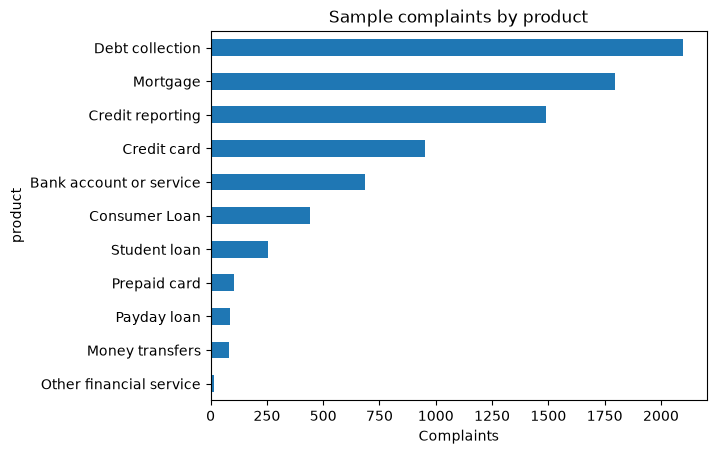

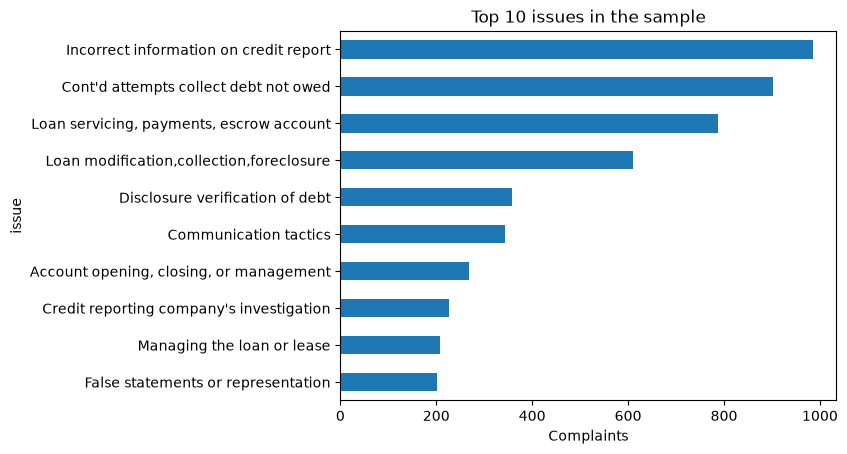


Example narrative (first 500 characters):
  product : Consumer Loan
  issue   : Problems when you are unable to pay
  text    : I am behind in my car payments due to unforseen personal circumstances. I had established a good standing with Wilshire up to the point of my default and and often paid early. I refinanced an existing loan only to have payment due in just 10 days. I have spoken to Wilshire several times about my inability to pay at this time and tried to work with them. Upon day 30 of my delinquency, they sent a repo man out to repossess my car and continue to call at all times of the day from various numbers. I


In [3]:
import matplotlib.pyplot as plt

# Product and issue counts are taken from the sample we will actually index and evaluate
product_counts = df_sample["product"].value_counts()
print("Complaints in the sample, by product:")
print(product_counts)
print(f"\nMost common product : {product_counts.index[0]} ({product_counts.iloc[0] / len(df_sample):.1%} of the sample)")

issue_counts = df_sample["issue"].value_counts()
print("\nTop 10 issues in the sample:")
print(issue_counts.head(10))

# Narrative length often differs by product (mortgage stories tend to be longer than a short billing dispute)
df_sample = df_sample.copy()
df_sample["narrative_chars"] = df_sample["narrative"].str.len()
print("\nNarrative length in characters, by product (median and mean):")
length_by_product = (
    df_sample.groupby("product")["narrative_chars"]
    .agg(["median", "mean", "count"])
    .sort_values("count", ascending=False)
)
print(length_by_product.round(0))

print("\nOverall narrative length in the sample:")
print(
    f"  min = {df_sample['narrative_chars'].min():,} | "
    f"median = {df_sample['narrative_chars'].median():.0f} | "
    f"mean = {df_sample['narrative_chars'].mean():.0f} | "
    f"max = {df_sample['narrative_chars'].max():,}"
)

ax = product_counts.sort_values().plot(kind="barh", title="Sample complaints by product")
ax.set_xlabel("Complaints")
plt.show()

ax = issue_counts.head(10).sort_values().plot(kind="barh", title="Top 10 issues in the sample")
ax.set_xlabel("Complaints")
plt.show()

# One example, so we can see the redacted style of a CFPB narrative
example = df_sample.iloc[0]
print("\nExample narrative (first 500 characters):")
print(f"  product : {example['product']}")
print(f"  issue   : {example['issue']}")
print(f"  text    : {example['narrative'][:500]}")


**Findings**
- The most common product in the sample is Debt collection (2,098 complaints, 26.2%), then Mortgage (1,794) and Credit reporting (1,489).
- The top issues line up with those products: incorrect information on a credit report (985), continued attempts to collect a debt not owed (902), and loan servicing, payments or escrow (787).
- Mortgage narratives are the longest (median 1,163 characters). The shortest medians are Credit reporting (519), Payday loan (534) and Debt collection (564). Overall median length is 753 characters (mean 1,051, max 5,153).
- The printed example is a Consumer Loan about falling behind on a car loan and a repossession attempt. This excerpt does not show `XXXX`, but later chunks in the notebook do; that is the official CFPB redaction of names and account numbers.
- **How to read this:** later, the random-retrieval baseline should sit close to the average product share. A precision@k well above that baseline means the embeddings are actually finding similar complaints.


## Step 3: Clean the Text and Chunk It
**What we do**
- Clean each narrative by collapsing whitespace and line breaks. We leave the CFPB `XXXX` redaction marks in place.
- Split each index narrative with LangChain's `RecursiveCharacterTextSplitter` (chunk size 500 characters, overlap 80).
- Store the product, issue and complaint id with every chunk, and show how one complaint was split.

**Why it matters**
- A retriever matches against chunks, not against a whole 3,000-character story. If a useful sentence sits in the middle of a long narrative, chunking gives it a chance to be found.
- Overlap reduces the chance that a sentence is cut in half and lost.
- Chunks that are too small lose context; chunks that are too large mix several topics and hit the generator's input limit. 500 characters is a short paragraph and a simple starting point.

**Domain link**
- A single complaint can mention more than one issue (for example a mortgage payment and a credit-report listing). Chunking lets us retrieve the relevant part for a given question.
- JD-based: LangChain for the RAG pipeline. Domain-based: long, unstructured complaint letters.

**Interview line**
- "I used LangChain's RecursiveCharacterTextSplitter with a 500-character window and an 80-character overlap so a long complaint can still be retrieved by the paragraph that matches the query."


In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

def clean_text(text):
    # Keep the official CFPB "XXXX" redaction marks; they hide names and account numbers
    text = str(text).replace("\n", " ")
    text = " ".join(text.split())
    return text

df_index["narrative_clean"] = df_index["narrative"].map(clean_text)
df_holdout["narrative_clean"] = df_holdout["narrative"].map(clean_text)

# 500 characters is a short paragraph; 80 characters of overlap reduces a sentence being cut in half
splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=80,
    separators=["\n\n", "\n", ". ", " ", ""],
)

chunk_texts = []
chunk_meta = []
for _, row in df_index.iterrows():
    pieces = splitter.split_text(row["narrative_clean"])
    for chunk_i, piece in enumerate(pieces):
        chunk_texts.append(piece)
        chunk_meta.append(
            {
                "complaint_id": row["complaint_id"],
                "product": row["product"],
                "issue": row["issue"],
                "chunk_i": chunk_i,
                "n_chunks": len(pieces),
            }
        )

print(f"Index complaints             : {len(df_index):,}")
print(f"Chunks after splitting       : {len(chunk_texts):,}")
print(f"Average chunks per complaint : {len(chunk_texts) / len(df_index):.2f}")

chunk_lens = pd.Series([len(t) for t in chunk_texts])
print("\nChunk length in characters:")
print(
    f"  min = {chunk_lens.min()} | "
    f"median = {chunk_lens.median():.0f} | "
    f"mean = {chunk_lens.mean():.0f} | "
    f"max = {chunk_lens.max()}"
)

# Show how one complaint is split, so the overlap is visible
sample_id = df_index.iloc[0]["complaint_id"]
sample_chunks = [
    (m["chunk_i"], t)
    for t, m in zip(chunk_texts, chunk_meta)
    if m["complaint_id"] == sample_id
]
print(f"\nExample: complaint_id {sample_id} was split into {len(sample_chunks)} chunk(s):")
for chunk_i, text in sample_chunks:
    print(f"\n--- chunk {chunk_i} ({len(text)} characters) ---")
    print(text)


Index complaints             : 7,600
Chunks after splitting       : 22,274
Average chunks per complaint : 2.93

Chunk length in characters:
  min = 6 | median = 407 | mean = 370 | max = 500

Example: complaint_id 1694983 was split into 1 chunk(s):

--- chunk 0 (324 characters) ---
We were discharged from chapter XXXX. Our home is underwater and wife being out of work since XXXX 2015. We ask Our second lender ( Carrington ) to settle the debt so we can retain the property. They only offered help with a short sale. In a short sale they wo n't get nothing. We never reaffirmed the loan. Can you help us?


**Findings**
- 7,600 index complaints were split into 22,274 chunks, or 2.93 chunks per complaint on average.
- Chunk length ranges from 6 to 500 characters (median 407, mean 370). The minimum of 6 is a leftover sliver from the splitter; most chunks are a short paragraph.
- The example (complaint 1694983) was only 324 characters, so it stayed as a single chunk and there is no overlap to see. Overlap would appear only when a narrative is longer than 500 characters.
- **How to read this:** an average a little above 2 chunks per complaint is consistent with a median narrative of several hundred characters and a 500-character window.


## Step 4: Embed the Chunks and Build a FAISS Index
**What we do**
- Load the sentence-transformers model `all-MiniLM-L6-v2` and print the embedding dimension.
- Embed every chunk, normalising the vectors so their length is 1.
- Add the vectors to a FAISS `IndexFlatIP` (inner-product search) and confirm the vector count.

**Why it matters**
- The embedding is what makes "similar meaning" searchable. Keyword search would miss a complaint that says "I did not authorise this payment" when the query says "unauthorized charges".
- Normalising, then using inner product, is cosine similarity: 1 means the same direction, 0 means unrelated, and negative values mean opposite directions.
- `IndexFlatIP` is exact search, not an approximate index. It is the simple, exact choice at this size (thousands of chunks, not millions).

**Domain link**
- A complaints team often starts from a free-text description, not from a product code. Dense retrieval can surface similar past cases even when the wording differs.
- JD-based: "embeddings" and "vector databases". Domain-based: similar-case search for complaint handling.

**Interview line**
- "I embedded each chunk with all-MiniLM-L6-v2 into 384 dimensions and stored the normalised vectors in a FAISS IndexFlatIP, which is exact cosine search at this scale."


In [5]:
from sentence_transformers import SentenceTransformer
import faiss

embed_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# One sample vector so we can print the dimension before embedding the full index
sample_vec = embed_model.encode(["unauthorized credit card charges"], normalize_embeddings=True)
print(f"Embedding model        : all-MiniLM-L6-v2")
print(f"Embedding dimension    : {sample_vec.shape[1]}")

# Normalising means inner product equals cosine similarity, which is a good default for this model
chunk_emb = embed_model.encode(
    chunk_texts,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
)
chunk_emb = np.asarray(chunk_emb, dtype="float32")
print(f"Chunk embedding matrix : {chunk_emb.shape[0]:,} rows x {chunk_emb.shape[1]} dimensions")

index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
print(f"Vectors in the FAISS index: {index.ntotal:,}")
print("Index type: IndexFlatIP (exact inner-product search on normalised vectors)")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model        : all-MiniLM-L6-v2
Embedding dimension    : 384


Batches:   0%|          | 0/349 [00:00<?, ?it/s]

Chunk embedding matrix : 22,274 rows x 384 dimensions
Vectors in the FAISS index: 22,274
Index type: IndexFlatIP (exact inner-product search on normalised vectors)


**Findings**
- The model is all-MiniLM-L6-v2. Each chunk is a 384-dimension vector. The embedding matrix is 22,274 rows by 384 dimensions.
- The FAISS index also holds 22,274 vectors, which matches the chunk count from Step 3.
- **How to read this:** MiniLM is 384 dimensions. The index should hold exactly one vector per chunk.


## Step 5: Retrieval Demo
**What we do**
- Write a small `search` function that embeds a query and returns the top-k chunks with their cosine scores, product and issue.
- Run three questions that a complaints team might actually ask, including "customers complaining about unauthorized credit card charges".
- Print the top 5 chunks for each question.

**Why it matters**
- This is the check you should do by eye before you compute a metric. If a question about unauthorised card charges returns mortgage-servicing chunks, the index is not ready to feed a generator.
- Showing the product, issue and a text snippet makes the retrieval inspectable, which matters when you later talk about grounding.

**Domain link**
- Typical themes in this file include unauthorised card charges, mortgage servicing errors, and debt-collection contact about a debt the consumer says is not owed. Those are everyday case types on a complaints desk.
- JD-based: retrieval step of RAG. Domain-based: similar-case lookup for a new complaint.

**Interview line**
- "I first check retrieval by hand: for a question about unauthorised card charges, I expect credit-card billing or fraud narratives near the top, not mortgage or student-loan chunks."


In [6]:
def search(query, k=5):
    """Return the k most similar chunks for a query, with metadata and cosine scores."""
    query_emb = embed_model.encode([query], normalize_embeddings=True)
    query_emb = np.asarray(query_emb, dtype="float32")
    scores, ids = index.search(query_emb, k)
    hits = []
    for rank, (score, idx) in enumerate(zip(scores[0], ids[0]), start=1):
        meta = chunk_meta[idx]
        hits.append(
            {
                "rank": rank,
                "score": float(score),
                "product": meta["product"],
                "issue": meta["issue"],
                "complaint_id": meta["complaint_id"],
                "text": chunk_texts[idx],
            }
        )
    return hits


def print_hits(query, hits):
    print(f"Query: {query}")
    print("-" * 80)
    for h in hits:
        print(
            f"Rank {h['rank']} | cosine = {h['score']:.3f} | "
            f"product = {h['product']} | issue = {h['issue']}"
        )
        print(f"  complaint_id = {h['complaint_id']}")
        print(f"  {h['text'][:350]}")
        print()


demo_queries = [
    "customers complaining about unauthorized credit card charges",
    "mortgage servicer lost my payment and charged late fees",
    "debt collector keeps calling about a debt I do not owe",
]

# Keep the first demo query so later cells can reuse it
demo_hits = None
for q in demo_queries:
    hits = search(q, k=5)
    if demo_hits is None:
        demo_hits = hits
    print_hits(q, hits)
    print()


Query: customers complaining about unauthorized credit card charges
--------------------------------------------------------------------------------
Rank 1 | cosine = 0.725 | product = Credit card | issue = Billing statement
  complaint_id = 1759696
  In XXXX XXXX, there were a number of unauthorized uses of my credit card-all to places in XXXX XXXX. A XXXX representative called me in XXXX to ask me about such charges and agreed that they were fraudulent, and that they would be taken off my bill. I paid the bill minus these charges. However, for several months after, these charges kept reappeari

Rank 2 | cosine = 0.691 | product = Credit card | issue = Identity theft / Fraud / Embezzlement
  complaint_id = 1627449
  . Because I was in a geographic area where these companies may or may not have been located, I am not going to accept XXXX 's word on that fact, my card company is going to try and make me responsible for charges that I never authorized or took part in? Absolutely unbeliev

Query: debt collector keeps calling about a debt I do not owe
--------------------------------------------------------------------------------
Rank 1 | cosine = 0.804 | product = Debt collection | issue = Cont'd attempts collect debt not owed
  complaint_id = 1386886
  Debt collector calling me about a payment from XXXX that I do not owe. Every time I ask tell them that XXXX has never contacted me XXXX telling me I owe a dime. I have received nothing in writing from XXXX. I keep telling them that I need it in writing from XXXX before I even think about giving them one cent. This company calls me every single day 

Rank 2 | cosine = 0.803 | product = Debt collection | issue = Improper contact or sharing of info
  complaint_id = 1610349
  Debt Collector contacted my office and told the person answering the phone that I need to pay my debt.

Rank 3 | cosine = 0.771 | product = Debt collection | issue = Improper contact or sharing of info
  complaint_id = 1526714
  The debt collector repea

**Findings**
- All three demo queries retrieved the right product in every one of the top 5 chunks. Unauthorised card charges came back as Credit card (billing, identity theft / fraud, and transaction issues). The lost mortgage payment came back as Mortgage loan servicing. The debt-collector calls came back as Debt collection (debt not owed, improper contact, and communication tactics). The snippets are clearly on topic, such as "unauthorized uses of my credit card" and "Debt collector calling me about a payment from XXXX that I do not owe".
- Good matches in this demo have cosine scores of about 0.67 to 0.80. The top hits are 0.725 (unauthorised charges), 0.765 (mortgage late fees) and 0.804 (debt not owed).
- **How to read this:** scores are cosine similarities, so they usually sit between about 0 and 1 here. A higher score is more similar, but you should still read the text, not only the number.


## Step 6: Retrieval Evaluation (precision@k)
**What we do**
- For each held-out complaint, use the first 500 characters of the narrative as the query and retrieve k = 5 chunks from the index (the holdout itself is not in the index).
- Score precision@k as the share of those 5 chunks whose `product` matches the held-out complaint's product.
- Also report the hit rate (at least one of the 5 matches), a random-retrieval baseline from the index product mix, a majority-product baseline, and precision by product.

**Why it matters**
- A demo of three questions is not an evaluation. Precision@k on held-out complaints is a simple, repeatable check that retrieval is better than guessing from the product mix.
- The first 500 characters are used because MiniLM truncates at 256 tokens. Capping the query makes that limit visible instead of hidden.

**Stats used:** precision@k, hit rate, random-retrieval baseline, majority baseline.

**Domain link**
- Product is only a proxy for relevance. Two credit-card complaints can be about very different issues, and a useful cross-product neighbour (for example credit reporting about a card account) would be counted as a miss. A stronger evaluation would use human relevance labels or an issue-level match.
- JD-based: evaluation of a RAG retriever. Domain-based: whether similar-case search returns the right product family.

**Interview line**
- "I held out 400 complaints, measured precision@5 against the product label, and compared it with a random baseline from the index product mix so the number has a floor to beat."


In [7]:
K = 5

# Use the start of each held-out narrative as the query.
# MiniLM truncates at 256 tokens, so we also cap the query at 500 characters to make that limit visible.
precisions = []
hit_any = []  # 1 if at least one of the k chunks has the same product

for _, row in df_holdout.iterrows():
    query = row["narrative_clean"][:500]
    hits = search(query, k=K)
    matches = [h["product"] == row["product"] for h in hits]
    precisions.append(sum(matches) / len(hits) if hits else 0.0)
    hit_any.append(int(any(matches)))

mean_precision = float(np.mean(precisions))
hit_rate = float(np.mean(hit_any))

# Random baseline: if we picked chunks in proportion to the index product mix,
# expected precision equals the share of index chunks with the query's product
chunk_product = pd.Series([m["product"] for m in chunk_meta])
chunk_share = chunk_product.value_counts(normalize=True)
random_baseline = float(df_holdout["product"].map(chunk_share).mean())

# Majority baseline: always retrieving the most common index product
majority_product = chunk_share.idxmax()
majority_baseline = float((df_holdout["product"] == majority_product).mean())

print(f"Held-out complaints              : {len(df_holdout):,}")
print(f"k                                : {K}")
print(f"Mean precision@{K}                 : {mean_precision:.1%}")
print(f"Hit rate (at least one match)    : {hit_rate:.1%}")
print(f"Random-retrieval baseline        : {random_baseline:.1%}")
print(f"Majority-product baseline        : {majority_baseline:.1%}  (always '{majority_product}')")

# Precision by true product, to see where retrieval is stronger or weaker
by_product = (
    pd.DataFrame({"product": df_holdout["product"].values, "precision": precisions})
    .groupby("product")["precision"]
    .mean()
    .sort_values(ascending=False)
)
print(f"\nMean precision@{K} by the held-out complaint's product:")
print(by_product.map(lambda x: f"{x:.1%}"))

# One worked example from the holdout
ex = df_holdout.iloc[0]
ex_hits = search(ex["narrative_clean"][:500], k=K)
print("\nWorked example from the holdout:")
print(f"  true product : {ex['product']}")
print(f"  true issue   : {ex['issue']}")
print(f"  query start  : {ex['narrative_clean'][:240]}")
print()
print_hits("held-out complaint (first 500 characters)", ex_hits)
ex_p = sum(h["product"] == ex["product"] for h in ex_hits) / K
print(f"Precision@{K} on this example: {ex_p:.1%}")


Held-out complaints              : 400
k                                : 5
Mean precision@5                 : 69.5%
Hit rate (at least one match)    : 93.2%
Random-retrieval baseline        : 17.7%
Majority-product baseline        : 22.5%  (always 'Mortgage')

Mean precision@5 by the held-out complaint's product:
product
Mortgage                   85.8%
Student loan               72.3%
Debt collection            71.0%
Credit reporting           69.5%
Prepaid card               68.0%
Credit card                65.4%
Bank account or service    57.1%
Consumer Loan              41.8%
Money transfers            30.0%
Payday loan                20.0%
Other financial service     0.0%
Name: precision, dtype: str

Worked example from the holdout:
  true product : Credit card
  true issue   : Billing statement
  query start  : Macy 's credit card website is designed to confuse its credit holder. I enrolled paperless statement, but the website does n't offer download monthly statement in PDF fil

**Findings**
- Mean precision@5 is 69.5% and the hit rate (at least one of the 5 chunks has the same product) is 93.2%, on 400 held-out complaints. That is well above the random-retrieval baseline of 17.7% and the majority-product baseline of 22.5% (always Mortgage in the chunk mix, because mortgage narratives are longer and produce more chunks).
- Precision@5 is strongest for Mortgage (85.8%), then Student loan (72.3%), Debt collection (71.0%) and Credit reporting (69.5%). It is weaker on rarer products: Consumer Loan 41.8%, Money transfers 30.0%, Payday loan 20.0%, and Other financial service 0.0% (very few holdout rows).
- The worked holdout example is a Credit card billing-statement complaint about a Macy's card website. All 5 retrieved chunks are also Credit card billing or related card issues, so precision@5 is 100.0% on this example.
- **How to read this:** precision@5 should be clearly above the random baseline. If it is not, the embeddings or the chunking need work before you trust the generator.


## Step 7: Answer Generation with Flan-T5
**What we do**
- Load the small open model `google/flan-t5-base` (no API key).
- For each question, retrieve 4 chunks, build a prompt that says "use only these excerpts", and generate a short answer.
- Print the retrieved products and the generated answer.

**Why it matters**
- This is the "G" in RAG. The model should not answer from memory alone; the prompt gives it the retrieved excerpts and allows it to say it does not have enough information.
- Flan-T5-base is small and runs on a CPU. The answers will be shorter and less fluent than a large chat model, which is an acceptable trade-off for a free, reproducible notebook.
- Flan-T5 accepts at most 512 input tokens, so the excerpts are truncated. That limit is a real design constraint, not just a technical detail.

**Domain link**
- A complaints officer can use the answer as a draft summary of similar past cases, then open the underlying narratives. The model should not be the final decision on a consumer case.
- JD-based: RAG generation step, with a path to AWS Bedrock. Domain-based: grounded drafting for complaint handling.

**Interview line**
- "I generate answers only from the retrieved excerpts, with a small open model so the notebook needs no API key, and I would swap that generator for AWS Bedrock in production."


In [8]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

gen_name = "google/flan-t5-base"
tokenizer = AutoTokenizer.from_pretrained(gen_name)
gen_model = AutoModelForSeq2SeqLM.from_pretrained(gen_name)
print(f"Generator loaded: {gen_name}")


def build_prompt(question, hits, max_context_chars=1200):
    # Flan-T5 has a 512-token input limit, so the excerpts must stay short.
    # This model follows a simple context / question / answer pattern well.
    parts = [f"[{h['product']}] {h['text']}" for h in hits]
    context = "\n\n".join(parts)[:max_context_chars]
    prompt = (
        "Answer the question using only the context. "
        "If the context is not enough, say you do not have enough information.\n\n"
        f"context: {context}\n\n"
        f"question: {question}\n"
        "answer:"
    )
    return prompt


def generate_answer(question, k=4):
    hits = search(question, k=k)
    prompt = build_prompt(question, hits)
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=512)
    output_ids = gen_model.generate(**inputs, max_new_tokens=128)
    answer = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return hits, prompt, answer


gen_questions = [
    "What problems do customers report with unauthorized credit card charges?",
    "What problems are customers reporting with mortgage loan servicing?",
]

gen_examples = []
for question in gen_questions:
    hits, prompt, answer = generate_answer(question, k=4)
    gen_examples.append((question, hits, answer))
    print("Question:")
    print(f"  {question}")
    print("\nRetrieved products and issues:")
    for h in hits:
        print(f"  rank {h['rank']}: {h['product']} | {h['issue']} | cosine = {h['score']:.3f}")
    print("\nGenerated answer:")
    print(f"  {answer}")
    print("\n" + "=" * 80 + "\n")


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Generator loaded: google/flan-t5-base


Question:
  What problems do customers report with unauthorized credit card charges?

Retrieved products and issues:
  rank 1: Credit card | Billing statement | cosine = 0.672
  rank 2: Credit card | Identity theft / Fraud / Embezzlement | cosine = 0.657
  rank 3: Credit card | Identity theft / Fraud / Embezzlement | cosine = 0.656
  rank 4: Credit card | Identity theft / Fraud / Embezzlement | cosine = 0.653

Generated answer:
  They have a rewards balance of $77.00 and they will NOT even acknowledge the fact they failed to pick up on any fraud.




Question:
  What problems are customers reporting with mortgage loan servicing?

Retrieved products and issues:
  rank 1: Mortgage | Loan servicing, payments, escrow account | cosine = 0.659
  rank 2: Mortgage | Loan servicing, payments, escrow account | cosine = 0.633
  rank 3: Mortgage | Loan modification,collection,foreclosure | cosine = 0.628
  rank 4: Mortgage | Loan servicing, payments, escrow account | cosine = 0.625

Generated answer:
  They do not care about their customers.




### How the same chain would use AWS Bedrock
The snippet below is **illustrative only** and is **not executed**. It shows how the same retrieved excerpts would be sent to a model hosted on AWS Bedrock (for example Claude or Amazon Titan) instead of Flan-T5. Running it would need a configured AWS account with Bedrock access, which this notebook does not use.

```python
# Illustrative only — not executed.
# The retriever stays the same; only the generator changes.

# from langchain_aws import ChatBedrock
# from langchain_core.prompts import ChatPromptTemplate
#
# llm = ChatBedrock(
#     model_id="anthropic.claude-3-haiku-20240307-v1:0",  # illustrative model id
#     region_name="us-east-1",
# )
#
# prompt = ChatPromptTemplate.from_template(
#     "Use only the complaint excerpts to answer the question. "
#     "If they are not enough, say you do not have enough information.\n\n"
#     "Excerpts:\n{context}\n\n"
#     "Question: {question}\n"
#     "Answer:"
# )
#
# hits = search(question, k=4)
# context = "\n\n".join(f"[{h['product']}] {h['text']}" for h in hits)
# chain = prompt | llm
# response = chain.invoke({"context": context, "question": question})
# print(response.content)
```

**Why Bedrock is a natural next step**
- The JD names AWS Bedrock. In a bank you often want the generator on a managed, access-controlled service rather than a model file in the notebook.
- Retrieval does not change: you still embed the query, search FAISS, and pass the top chunks into the prompt.
- You would add logging of the retrieved complaint ids, access control, and a human review step before anything is sent back to a customer.


**Findings**
- Question 1, "What problems do customers report with unauthorized credit card charges?": the top 4 chunks are all Credit card (billing and identity theft / fraud). The generated answer is: "They have a rewards balance of $77.00 and they will NOT even acknowledge the fact they failed to pick up on any fraud." It mentions fraud, which fits the retrieved issues, but the specific "$77.00 rewards balance" is a detail we cannot confirm from the printed snippets.
- Question 2, "What problems are customers reporting with mortgage loan servicing?": the top 4 chunks are all Mortgage, mostly loan servicing, payments and escrow (cosine 0.625 to 0.659). The generated answer is: "They do not care about their customers." That is vague and does not mention the late fees and unapplied payments in the retrieved excerpts.
- Retrieval is on-topic, but Flan-T5-base often produces a short or generic sentence rather than a careful grounded summary. That is why a production version would swap this generator for a stronger model on AWS Bedrock.
- **How to read this:** Flan-T5-base is a small model, so answers may be short or slightly stiff. The quality test is grounding (does it stick to the excerpts?), not fluency.


## Step 8: Optional Bonus – Product Classifier
**What we do**
- Embed each index complaint and each held-out complaint as a single vector, using the same MiniLM model.
- Fit a logistic regression with `class_weight='balanced'` to predict `product`.
- Report accuracy, weighted F1, a majority-product baseline, and a classification report on the holdout.

**Why it matters**
- The same embeddings used for RAG can also route a new complaint to a product team. That is a simple, explainable baseline next to the retrieval path.
- `class_weight='balanced'` gives rarer products (payday loan, money transfers, prepaid card) more weight so the model does not only predict the largest classes.

**Stats used:** accuracy, weighted F1, majority-class baseline, per-class precision and recall.

**Domain link**
- A complaints inbox is often routed by product or issue before a specialist reviews it. An embedding classifier can pre-assign that route; a human should still confirm it.
- JD-based: a classical ML baseline alongside the GenAI pipeline. Domain-based: complaint routing.

**Interview line**
- "I also trained a logistic regression on the same MiniLM embeddings to predict product, and I compared it with a majority-class baseline on the same held-out complaints."


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# One embedding per complaint (not per chunk), using the same MiniLM model
X_train = embed_model.encode(
    df_index["narrative_clean"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
)
X_test = embed_model.encode(
    df_holdout["narrative_clean"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,
)
y_train = df_index["product"]
y_test = df_holdout["product"]

# class_weight helps the rarer products (payday loan, money transfers, prepaid card)
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred, average="weighted")
# A simple baseline: always predict the most common product in the index
majority_pred = [y_train.value_counts().idxmax()] * len(y_test)
maj_acc = accuracy_score(y_test, majority_pred)

print(f"Held-out complaints              : {len(y_test):,}")
print(f"Logistic regression accuracy     : {acc:.1%}")
print(f"Weighted F1                      : {f1:.1%}")
print(f"Majority-product baseline acc.   : {maj_acc:.1%}  (always '{y_train.value_counts().idxmax()}')")
print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))


Batches:   0%|          | 0/119 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Held-out complaints              : 400
Logistic regression accuracy     : 77.2%
Weighted F1                      : 78.5%
Majority-product baseline acc.   : 26.2%  (always 'Debt collection')

Classification report:
                         precision    recall  f1-score   support

Bank account or service       0.69      0.74      0.71        34
          Consumer Loan       0.68      0.68      0.68        22
            Credit card       0.69      0.71      0.70        48
       Credit reporting       0.81      0.76      0.78        74
        Debt collection       0.90      0.73      0.81       105
        Money transfers       0.57      1.00      0.73         4
               Mortgage       0.93      0.90      0.92        90
Other financial service       0.00      0.00      0.00         1
            Payday loan       0.12      0.50      0.20         4
           Prepaid card       0.33      0.60      0.43         5
           Student loan       0.71      0.92      0.80        13

    

**Findings**
- Logistic regression accuracy is 77.2% and weighted F1 is 78.5% on the 400 held-out complaints, well above the majority-product baseline of 26.2% (always Debt collection).
- Mortgage is classified best (F1 0.92), then Debt collection (0.81), Student loan (0.80) and Credit reporting (0.78). Credit card and bank-account complaints are solid (F1 about 0.70). The rare products are weaker: Payday loan (F1 0.20, only 4 holdout rows), Prepaid card (0.43, 5 rows) and Other financial service (0.00, 1 row).
- **How to read this:** accuracy should beat the majority baseline. This classifier is a routing aid, not a replacement for retrieval or for reading the complaint.


## Summary for Interview
**Results**
- Data: 555,957 rows in the full file; 66,806 with a narrative (12.0%); 8,000 sampled, with 7,600 in the index and 400 held out; 22,274 chunks.
- Embeddings: all-MiniLM-L6-v2, 384 dimensions, 22,274 vectors in the FAISS index.
- Retrieval: mean precision@5 69.5%, hit rate 93.2%, random baseline 17.7%, majority baseline 22.5% (Mortgage in the chunk mix).
- Generation: retrieval stayed on the right product, but Flan-T5-base answers were short and only loosely grounded (one named an unconfirmed "$77.00 rewards balance"; the mortgage answer was only "They do not care about their customers.").
- Product classifier: accuracy 77.2%, weighted F1 78.5%, vs a 26.2% majority baseline.

**Limitations**
- The public file is US CFPB complaints, not this organisation's own case system, and only the consented narratives are available.
- We sample 8,000 narratives, so rare products and newer complaint types may be under-represented.
- MiniLM truncates at 256 tokens and Flan-T5 at 512 input tokens, so long narratives and long contexts are cut.
- Precision@k uses `product` as a proxy label, not a human judgement of relevance. A cross-product but still useful neighbour is counted as a miss.
- Flan-T5-base is a small model; answers can be short or imperfectly grounded. It is a free stand-in for a production LLM.
- Medians, baselines and the classifier all use this same sample; a later time period of complaints would be a stronger test.
- Names and account numbers are already redacted as `XXXX`, but a production system would still need a privacy review before any text is logged or sent to a hosted model.

**Next steps**
- Swap Flan-T5 for AWS Bedrock (or another approved model) using the same retriever and prompt template, with complaint-id logging and human review.
- Improve evaluation with issue-level or human relevance labels, and add a refusal test for questions the index cannot support.
- Refresh the index on a schedule as new complaints arrive, and watch precision@k and user feedback for drift.
- Deployment: a small FastAPI or Streamlit app where an analyst pastes a complaint, sees the top-k similar cases, and edits a grounded draft.


## Common Interview Questions
Short hints only. Answer in your own words using your numbers.

- **1. What is RAG, and why not send the question to an LLM alone?**
  - Hint: an LLM alone can hallucinate and does not know this organisation's complaint history. RAG first retrieves relevant excerpts from our own (here, public CFPB) narratives, then asks the model to answer using those excerpts. The answer can be traced back to complaint ids.
- **2. Why do you chunk the narratives?**
  - Hint: many complaints are longer than the retriever's useful window, and a query may match only one part of a long story. Chunks with a small overlap let us retrieve the relevant paragraph. Too small a chunk loses context; too large a chunk mixes topics and blows the generator's 512-token limit.
- **3. What is an embedding, and why all-MiniLM-L6-v2?**
  - Hint: an embedding is a vector that represents meaning. MiniLM maps each chunk to 384 numbers and is small enough to run on a CPU. I would consider a stronger embedding model if recall on hard queries was weak, but I would not start with a large model for a first pass.
- **4. What is a vector database, and why FAISS?**
  - Hint: a vector database searches by similarity in embedding space, not by exact keywords. FAISS `IndexFlatIP` is exact cosine search once vectors are normalised. At a few thousand chunks we do not need an approximate index (IVF or HNSW). At millions of chunks we would.
- **5. How did you evaluate the retriever?**
  - Hint: I held out 400 complaints, used the start of each narrative as a query, and computed precision@5 against the product label, plus a random baseline from the index product mix. Product is a proxy, so I would also do a manual read of retrieved text and, in production, collect human relevance labels.
- **6. What is the difference between hallucination and grounding?**
  - Hint: grounding means the answer is supported by retrieved excerpts. Hallucination is an invented detail that is not in those excerpts. I reduce the risk with a "use only the excerpts" prompt and a way to say "not enough information", but I still check answers against the chunks before anything goes to a customer.
- **7. How would you use AWS Bedrock in this pipeline?**
  - Hint: retrieval stays the same. I would pass the same excerpts and prompt to a Bedrock model (for example Claude or Titan) through an approved AWS account, then log the complaint ids that were used. Bedrock is the managed generator; FAISS and the embeddings can stay in our environment or also move to AWS.
- **8. What data and privacy issues should you flag?**
  - Hint: only consented narratives are public; CFPB already redacts names and account numbers as `XXXX`; a bank's own complaints would be confidential and would need a privacy review before being sent to any hosted model, including Bedrock. I would not put raw customer identifiers into the prompt.
- **9. Why LangChain if you also call FAISS and MiniLM directly?**
  - Hint: LangChain gives a standard text splitter and, later, a standard way to swap the generator (including Bedrock). I kept the retriever in plain FAISS and sentence-transformers so the code is easy to explain and does not hide the steps behind a long chain class.
- **10. How would you deploy and monitor this for a complaints team?**
  - Hint: a simple app where an analyst pastes a complaint, sees top-k similar cases with links to the source, and edits a draft answer. I would log queries, retrieved ids and thumbs-up or thumbs-down, watch precision@k on a labelled sample, and rebuild the index as new complaints arrive.


## Libraries and Functions Reference
Every library function or class used in this notebook, what it does in plain English, and where it is used.

**pandas (pd)**
- `pd.read_csv()`: loads the CFPB CSV into a DataFrame; Step 1
- `DataFrame.isna().sum()`: counts missing values by column; Step 1
- `Series.duplicated()`: checks for repeated complaint ids; Step 1
- `Series.notna()`: marks rows that have a narrative; Step 1
- `Series.astype(str)` / `Series.str.len()`: treats the narrative as text and counts characters; Steps 1 and 2
- `DataFrame.loc[]` / `DataFrame.copy()`: keeps the narrative rows as a separate table; Step 1
- `DataFrame.rename()`: renames the long narrative column to `narrative`; Step 1
- `Series.value_counts()`: counts complaints by product or issue; Steps 1, 2, 6 and 8
- `DataFrame.reset_index()`: renumbers rows after a split; Step 1
- `DataFrame.groupby()` / `.agg()`: median and mean narrative length by product; Step 2
- `Series.sort_values()` / `Series.head()` / `Series.iloc[]`: order and pick rows or counts; Steps 2, 5 and 6
- `Series.map()`: applies a function or a lookup to each value; Steps 3 and 6
- `Series.plot()`: horizontal bar charts for product and issue; Step 2
- `pd.Series()` / `pd.DataFrame()`: wrap lists so we can average precision by product; Steps 3 and 6
- `DataFrame.iterrows()`: walks each index complaint when we chunk; Step 3

**numpy (np)**
- `np.asarray(..., dtype="float32")`: FAISS expects 32-bit float vectors; Steps 4 and 5
- `np.mean()`: average of precision@k and of the hit-rate flags; Step 6

**matplotlib.pyplot (plt)**
- `plt.show()`: displays the product and issue bar charts; Step 2
- `Axes.set_xlabel()`: labels the chart axis; Step 2

**scikit-learn**
- `train_test_split(stratify=)`: draws the 8,000-row sample and the 400-row holdout, keeping the product mix; Step 1
- `LogisticRegression(class_weight="balanced")`: the optional product classifier; Step 8
- `accuracy_score()` / `f1_score()`: overall classifier metrics; Step 8
- `classification_report()`: per-product precision, recall and F1; Step 8

**LangChain**
- `RecursiveCharacterTextSplitter`: splits a narrative into overlapping character chunks; Step 3
- `splitter.split_text()`: returns the list of chunks for one complaint; Step 3

**sentence-transformers**
- `SentenceTransformer()`: loads `all-MiniLM-L6-v2`; Step 4
- `model.encode(..., normalize_embeddings=True)`: turns texts into 384-dimension unit vectors; Steps 4, 5 and 8

**faiss**
- `faiss.IndexFlatIP()`: exact inner-product index; Step 4
- `index.add()`: stores the chunk vectors; Step 4
- `index.search()`: returns the k nearest vectors and their scores; Step 5
- `index.ntotal`: number of vectors stored; Step 4

**transformers**
- `AutoTokenizer.from_pretrained()`: loads the Flan-T5 tokenizer; Step 7
- `AutoModelForSeq2SeqLM.from_pretrained()`: loads the Flan-T5 generator; Step 7
- `tokenizer(..., return_tensors="pt", truncation=True, max_length=512)`: turns the prompt into token ids, truncated to the model limit; Step 7
- `model.generate()`: produces output token ids; Step 7
- `tokenizer.decode(..., skip_special_tokens=True)`: converts those ids back into text; Step 7

**os**
- `os.walk()` / `os.path.join()`: lists files under `/kaggle/input` so you can confirm the data path; first cell
